# NNLib vs PyTorch (same machine)
Both programs run here in the same Colab session, on the same CPU, with 1 thread each.
Same network: 784 → 128 (ReLU) → 10, SGD lr 0.1, batch 64, 5 epochs.

**Run the cells in order.**

## Step 1: upload your header files from `include/nnlib/`
Select the files inside `include/nnlib/`: `nnlib.h  matrix.h  init.h  layer.h  loss.h  optimizer.h  network.h  data.h`


In [2]:
from google.colab import files
uploaded = files.upload()
print(sorted(uploaded.keys()))

Saving layer.h to layer.h
Saving loss.h to loss.h
Saving matrix.h to matrix.h
Saving nnlib.h to nnlib.h
Saving optimizer.h to optimizer.h
Saving data.h to data.h
Saving init.h to init.h
Saving network.h to network.h
['data.h', 'init.h', 'layer.h', 'loss.h', 'matrix.h', 'network.h', 'nnlib.h', 'optimizer.h']


## Step 2: download MNIST

In [3]:
%%bash
mkdir -p data && cd data
for f in train-images-idx3-ubyte train-labels-idx1-ubyte t10k-images-idx3-ubyte t10k-labels-idx1-ubyte; do
  curl -sL -O https://github.com/golbin/TensorFlow-MNIST/raw/master/mnist/data/$f.gz && gunzip -f $f.gz
done
ls -l

total 53672
-rw-r--r-- 1 root root  7840016 Nov 16 12:06 t10k-images-idx3-ubyte
-rw-r--r-- 1 root root    10008 Nov 16 12:06 t10k-labels-idx1-ubyte
-rw-r--r-- 1 root root 47040016 Nov 16 12:06 train-images-idx3-ubyte
-rw-r--r-- 1 root root    60008 Nov 16 12:06 train-labels-idx1-ubyte


## Step 3: the machine we are measuring on

In [4]:
!lscpu | grep -E 'Model name|^CPU\(s\)'
!g++ --version | head -1
!python -c "import torch; print('torch', torch.__version__)"

CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
g++ (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
torch 2.14.1+cpu


## Step 4: nnlib benchmark (C++)

In [5]:
%%writefile bench.cpp
// Benchmark: training time per epoch + batch-1 inference latency.
// Same network as the PyTorch script: 784 -> 128 (ReLU) -> 10, SGD lr 0.1, batch 64.
#include <algorithm>
#include <chrono>
#include <iomanip>
#include <numeric>
#include <random>
#include <string>
#include <vector>
#include "nnlib.h"

using Clock = std::chrono::steady_clock;

Matrix get_rows(Matrix& m, std::vector<int>& idx, int start, int count) {
    Matrix out(count, m.cols);
    for (int i = 0; i < count; i++)
        for (int j = 0; j < m.cols; j++)
            out.at(i, j) = m.at(idx[start + i], j);
    return out;
}

int argmax_row(Matrix& m, int i) {
    int best = 0;
    for (int j = 1; j < m.cols; j++)
        if (m.at(i, j) > m.at(i, best)) best = j;
    return best;
}

float accuracy(Network& net, Matrix& x, Matrix& y) {
    Matrix scores = net.forward(x);
    int correct = 0;
    for (int i = 0; i < x.rows; i++)
        if (argmax_row(scores, i) == argmax_row(y, i)) correct++;
    return (float)correct / x.rows;
}

int main(int argc, char** argv) {
    std::string dir = argc > 1 ? argv[1] : "data";
    Matrix train_x = load_images(dir + "/train-images-idx3-ubyte", 60000);
    Matrix train_y = load_labels(dir + "/train-labels-idx1-ubyte", 60000);
    Matrix test_x = load_images(dir + "/t10k-images-idx3-ubyte", 10000);
    Matrix test_y = load_labels(dir + "/t10k-labels-idx1-ubyte", 10000);

    Network net(1);
    net.add(784, 128, Act::ReLU);
    net.add(128, 10, Act::None);
    Optimizer opt(Opt::SGD, 0.1f);

    const int epochs = 5, batch = 64;
    std::mt19937 gen(0);
    std::vector<int> order(train_x.rows);
    std::iota(order.begin(), order.end(), 0);

    std::cout << std::fixed << std::setprecision(4);

    // ---- 1. training speed ----
    for (int epoch = 1; epoch <= epochs; epoch++) {
        std::shuffle(order.begin(), order.end(), gen);
        auto t0 = Clock::now();

        float total_loss = 0;
        int batches = 0;
        for (int start = 0; start + batch <= train_x.rows; start += batch) {
            Matrix x = get_rows(train_x, order, start, batch);
            Matrix y = get_rows(train_y, order, start, batch);
            Matrix scores = net.forward(x);
            total_loss += cross_entropy_loss(scores, y);
            batches++;
            Matrix d_scores = cross_entropy_grad(scores, y);
            net.backward(d_scores);
            net.step(opt);
        }
        double secs = std::chrono::duration<double>(Clock::now() - t0).count();
        std::cout << "nnlib   epoch " << epoch << "  time " << secs << " s  loss " << total_loss / batches
                  << "  test acc " << accuracy(net, test_x, test_y) * 100 << "%\n";
    }

    // ---- 2. batch-1 inference latency ----
    std::vector<int> ids(1000);
    std::iota(ids.begin(), ids.end(), 0);
    std::vector<Matrix> singles;                       // 1000 single-image inputs, prepared in advance
    for (int i = 0; i < 1000; i++) singles.push_back(get_rows(test_x, ids, i, 1));

    for (int i = 0; i < 200; i++) net.forward(singles[i % 1000]);        // warm-up

    const int runs = 10000;
    std::vector<double> us(runs);
    for (int i = 0; i < runs; i++) {
        auto t0 = Clock::now();
        Matrix out = net.forward(singles[i % 1000]);
        us[i] = std::chrono::duration<double, std::micro>(Clock::now() - t0).count();
    }
    std::sort(us.begin(), us.end());
    std::cout << "nnlib   batch-1 latency:  p50 " << us[runs / 2] << " us   p99 " << us[runs * 99 / 100] << " us\n";
}


Writing bench.cpp


In [6]:
!g++ -std=c++17 -O3 -march=native bench.cpp -o bench && ./bench data

nnlib   epoch 1  time 2.2267 s  loss 0.3691  test acc 93.9400%
nnlib   epoch 2  time 1.4228 s  loss 0.1963  test acc 95.4400%
nnlib   epoch 3  time 1.4862 s  loss 0.1487  test acc 96.0400%
nnlib   epoch 4  time 1.4440 s  loss 0.1203  test acc 96.5700%
nnlib   epoch 5  time 1.4420 s  loss 0.1021  test acc 96.8200%
nnlib   batch-1 latency:  p50 15.6250 us   p99 32.7700 us


## Step 5: PyTorch benchmark (same network, same settings)

In [7]:
%%writefile bench_pytorch.py
# Same network and settings as bench.cpp: 784 -> 128 (ReLU) -> 10, SGD lr 0.1, batch 64.
import sys
import time

import numpy as np
import torch
import torch.nn as nn

torch.set_num_threads(1)     # nnlib is single-threaded, so PyTorch gets 1 thread too
torch.manual_seed(0)
data_dir = sys.argv[1] if len(sys.argv) > 1 else "data"


def load_images(path):
    raw = open(path, "rb").read()
    n = int.from_bytes(raw[4:8], "big")
    return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, 784).astype(np.float32) / 255


def load_labels(path):
    raw = open(path, "rb").read()
    return np.frombuffer(raw, dtype=np.uint8, offset=8).astype(np.int64)


train_x = torch.from_numpy(load_images(f"{data_dir}/train-images-idx3-ubyte"))
train_y = torch.from_numpy(load_labels(f"{data_dir}/train-labels-idx1-ubyte"))
test_x = torch.from_numpy(load_images(f"{data_dir}/t10k-images-idx3-ubyte"))
test_y = torch.from_numpy(load_labels(f"{data_dir}/t10k-labels-idx1-ubyte"))

model = nn.Sequential(nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
# same starting weights recipe as nnlib: He for the ReLU layer, Xavier for the last, biases 0
nn.init.kaiming_normal_(model[0].weight, nonlinearity="relu")
nn.init.zeros_(model[0].bias)
nn.init.xavier_uniform_(model[2].weight)
nn.init.zeros_(model[2].bias)

opt = torch.optim.SGD(model.parameters(), lr=0.1)
loss_fn = nn.CrossEntropyLoss()
epochs, batch = 5, 64
n = train_x.shape[0]

# ---- 1. training speed ----
for epoch in range(1, epochs + 1):
    perm = torch.randperm(n)
    t0 = time.perf_counter()
    total_loss = 0.0
    batches = 0
    for start in range(0, n - batch + 1, batch):
        idx = perm[start:start + batch]
        x, y = train_x[idx], train_y[idx]
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step()
        total_loss += loss.item()
        batches += 1
    secs = time.perf_counter() - t0
    with torch.no_grad():
        acc = (model(test_x).argmax(1) == test_y).float().mean().item() * 100
    print(f"pytorch epoch {epoch}  time {secs:.4f} s  loss {total_loss / batches:.4f}  test acc {acc:.4f}%")

# ---- 2. batch-1 inference latency ----
singles = [test_x[i:i + 1] for i in range(1000)]
with torch.inference_mode():
    for i in range(200):                       # warm-up
        model(singles[i % 1000])
    runs = 10000
    us = []
    for i in range(runs):
        t0 = time.perf_counter()
        model(singles[i % 1000])
        us.append((time.perf_counter() - t0) * 1e6)
us.sort()
print(f"pytorch batch-1 latency:  p50 {us[runs // 2]:.4f} us   p99 {us[runs * 99 // 100]:.4f} us")


Writing bench_pytorch.py


In [8]:
!python bench_pytorch.py data

pytorch epoch 1  time 1.3861 s  loss 0.3723  test acc 93.1800%
pytorch epoch 2  time 1.1867 s  loss 0.2004  test acc 95.1000%
pytorch epoch 3  time 1.1987 s  loss 0.1502  test acc 95.9900%
pytorch epoch 4  time 1.2068 s  loss 0.1215  test acc 96.8100%
pytorch epoch 5  time 1.2379 s  loss 0.1015  test acc 97.0700%
pytorch batch-1 latency:  p50 34.6780 us   p99 102.7560 us


# Visualization of MNIST Training Loss and Batch-1 Inference Latency between **PyTorch** and **NNLib**

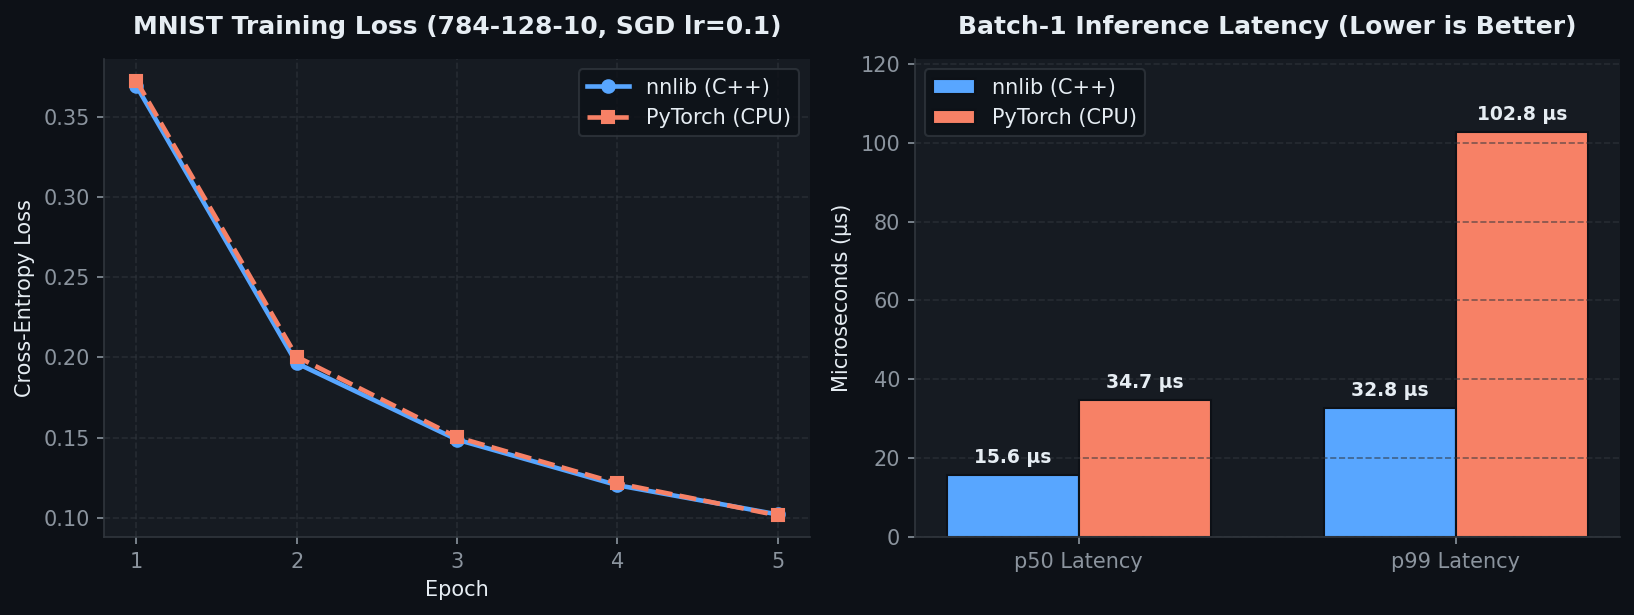

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# GitHub Dark theme palette
BG_FIG  = '#0d1117'
BG_AXES = '#161b22'
TEXT    = '#e6edf3'
MUTED   = '#8b949e'
GRID    = '#30363d'
C_NNLIB = '#58a6ff'  # Bright blue/cyan
C_TORCH = '#f78166'  # Warm coral/orange

plt.rcParams.update({
    'figure.facecolor': BG_FIG,
    'axes.facecolor':   BG_AXES,
    'axes.edgecolor':   GRID,
    'axes.labelcolor':  TEXT,
    'text.color':       TEXT,
    'xtick.color':      MUTED,
    'ytick.color':      MUTED,
    'grid.color':       GRID,
})

# Exact results from your Colab benchmark run
epochs       = [1, 2, 3, 4, 5]
nnlib_loss   = [0.3691, 0.1963, 0.1487, 0.1203, 0.1021]
pytorch_loss = [0.3723, 0.2004, 0.1502, 0.1215, 0.1015]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)

# Plot 1: Training Loss Convergence
ax1.plot(epochs, nnlib_loss, 'o-', color=C_NNLIB, linewidth=2.2, markersize=6, label='nnlib (C++)')
ax1.plot(epochs, pytorch_loss, 's--', color=C_TORCH, linewidth=2.2, markersize=6, label='PyTorch (CPU)')
ax1.set_title('MNIST Training Loss (784-128-10, SGD lr=0.1)', pad=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.set_xticks(epochs)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(facecolor=BG_FIG, edgecolor=GRID)

# Plot 2: Single-Image Inference Latency (lower is better)
metrics     = ['p50 Latency', 'p99 Latency']
nnlib_lat   = [15.62, 32.77]
pytorch_lat = [34.7, 102.75]

x = np.arange(len(metrics))
w = 0.35
b1 = ax2.bar(x - w/2, nnlib_lat, w, color=C_NNLIB, edgecolor=BG_FIG, label='nnlib (C++)')
b2 = ax2.bar(x + w/2, pytorch_lat, w, color=C_TORCH, edgecolor=BG_FIG, label='PyTorch (CPU)')

ax2.set_title('Batch-1 Inference Latency (Lower is Better)', pad=12, fontweight='bold')
ax2.set_ylabel('Microseconds (µs)')
ax2.set_xticks(x)
ax2.set_xticklabels(metrics)
ax2.set_ylim(0, max(pytorch_lat) * 1.18)  # Extra headroom for bar labels
ax2.grid(True, axis='y', linestyle='--', alpha=0.6)
ax2.legend(facecolor=BG_FIG, edgecolor=GRID)

ax2.bar_label(b1, fmt='%.1f µs', padding=4, fontsize=9, color=TEXT, fontweight='bold')
ax2.bar_label(b2, fmt='%.1f µs', padding=4, fontsize=9, color=TEXT, fontweight='bold')

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('benchmark.png', facecolor=BG_FIG, bbox_inches='tight')
plt.show()


## How to read the results
- **Loss and test acc must be close** between nnlib and PyTorch. If not, something is wrong and the speed numbers mean nothing.
- **epoch time**: training speed. PyTorch will probably win here (its matrix multiply is heavily tuned).
- **batch-1 latency**: time to run one image through the network. Small networks are where a simple C++ library can compete.
- Run the last two cells 2–3 times; timings are noisy on shared Colab machines. Report the median run, plus the CPU name from Step 3.